In [4]:
import numpy as np
import matplotlib as plt
from scipy.stats import norm, t, multivariate_t


In [ ]:

np.random.seed(39)

n = 1000
N = 10**5
pk = 0.03
nu = 3
mu = np.zeros(n)

def simulate_defaults(func, rho):

    cov = np.full((n, n), rho, dtype=float)
    np.fill_diagonal(cov, 1)

    if func == "n":

        Zn = np.random.multivariate_normal(mu, cov, size=N)
        d = norm.ppf(pk)

    elif func == "t":

        Zn = multivariate_t.rvs(
            loc=mu, shape=cov, df=nu, size=N
        )
        d = t.ppf(pk, df=nu)

    X = (Zn <= d).astype(int)

    N_defaults = np.sum(X, axis=1)

    return N_defaults



N_a = simulate_defaults("n", 0)
N_b = simulate_defaults("n", 0.1)
N_c = simulate_defaults("t", 0)
N_d = simulate_defaults("t", 0.1)
N_e = simulate_defaults("n", 0.5)
N_f = simulate_defaults("n", 0.9)
N_g = simulate_defaults("t", 0.5)



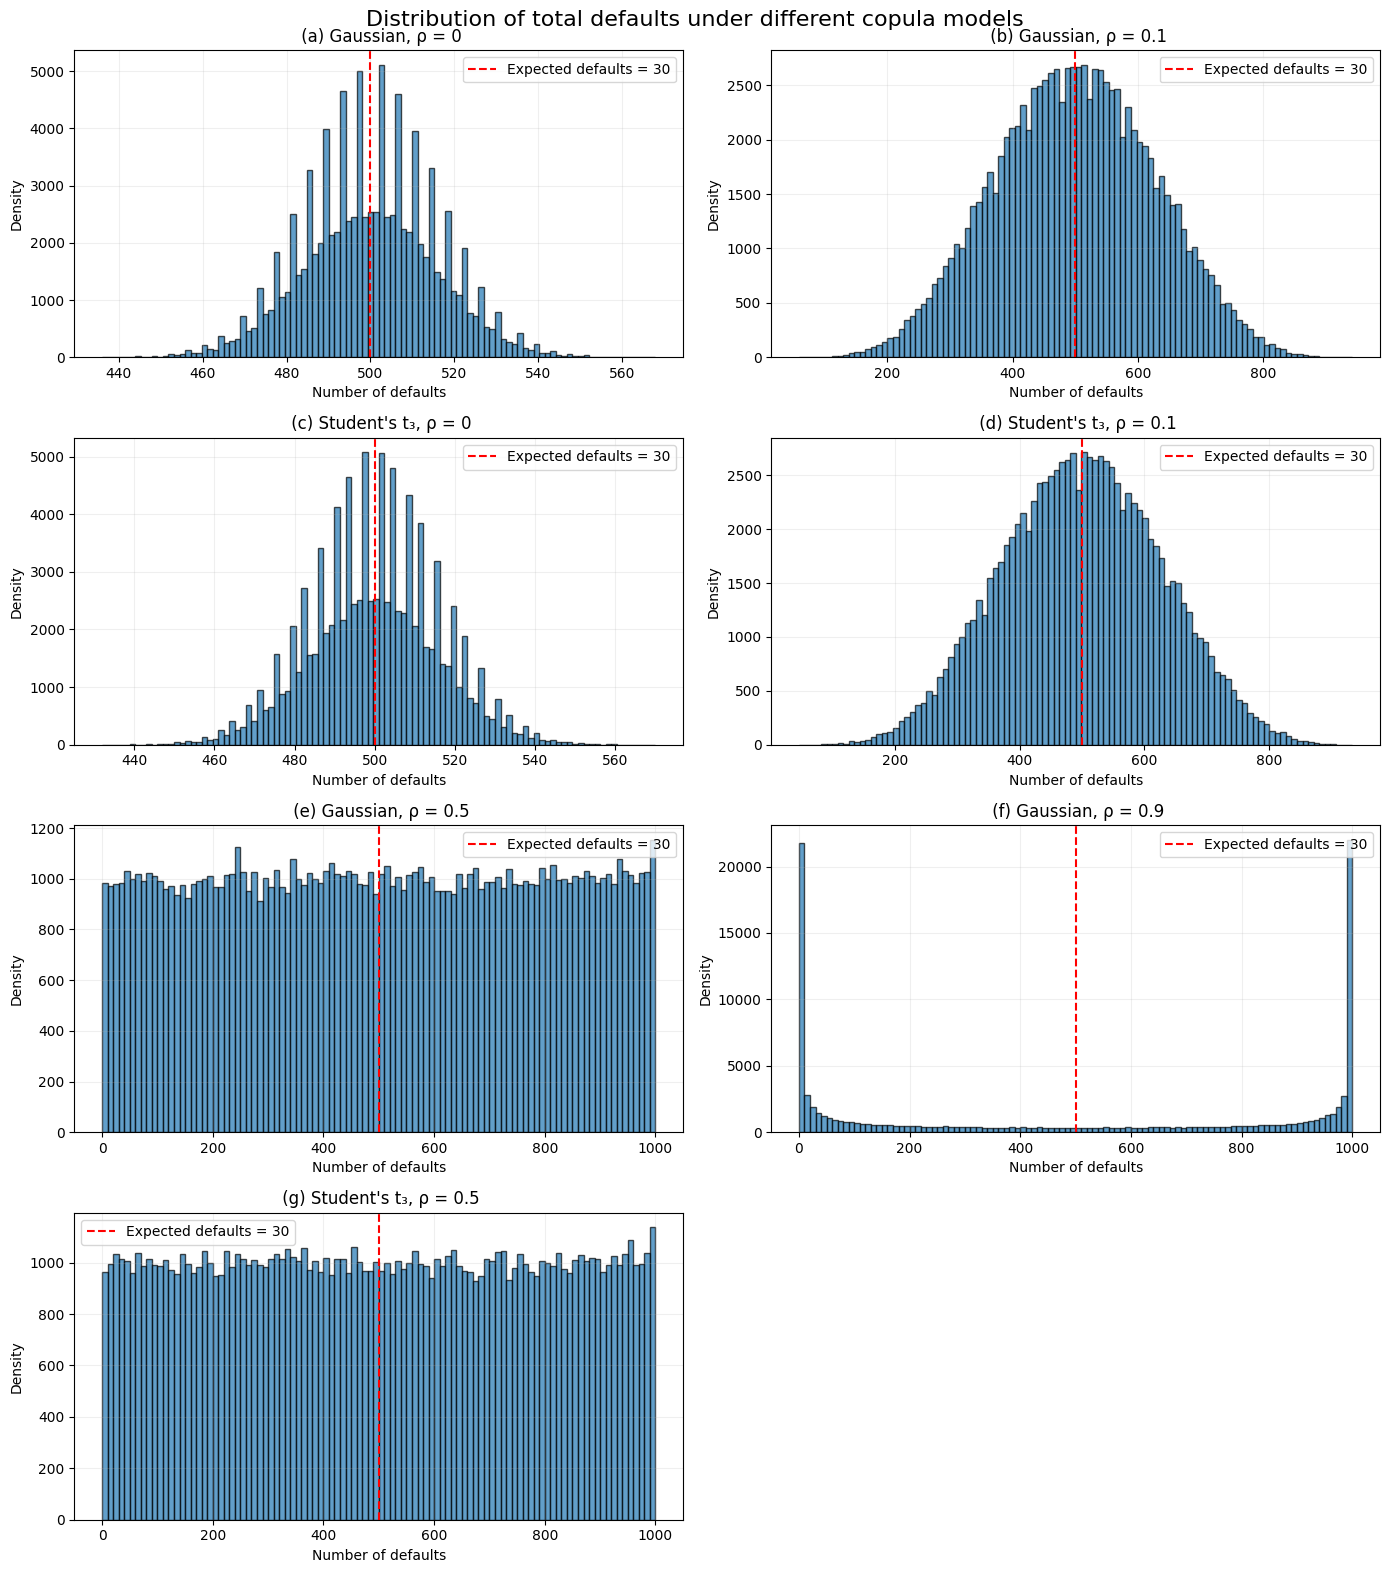

In [15]:
import matplotlib.pyplot as plt

models = [
    (N_a, " (a) Gaussian, ρ = 0"),
    (N_b, " (b) Gaussian, ρ = 0.1"),
    (N_c, " (c) Student's t₃, ρ = 0"),
    (N_d, " (d) Student's t₃, ρ = 0.1"),
    (N_e, " (e) Gaussian, ρ = 0.5"),
    (N_f, " (f) Gaussian, ρ = 0.9"),
    (N_g, " (g) Student's t₃, ρ = 0.5")
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for ax, (data, title) in zip(axes, models):

    ax.hist(data, bins=100, density=False,
            edgecolor="black", alpha=0.7)

    ax.axvline(n * pk, color="red", linestyle="--",
               label="Expected defaults = 30")

    ax.set_title(title)
    ax.set_xlabel("Number of defaults")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

# Remove unused subplot
fig.delaxes(axes[-1])

fig.suptitle("Distribution of total defaults under different copula models",
             fontsize=16)

plt.tight_layout()
plt.show()